DATA 266 Homework 12
LLM Optimization with GPTQ and Knowledge Distillation
This notebook implements Homework 12 end to end.

Personal parameters

SID4 = 2046
SEED = 2046
SLICE = 46
HP_ID = 0
CLS_A = 6
CLS_B = 3

Part 1 uses the model shown in the instructor linked Hugging Face GPTQ documentation: Qwen/Qwen3-0.6B.

Part 2 uses the instructor provided fine tuned BERT teacher and distilbert-base-uncased as the student.

In [ ]:
!pip install -q gptqmodel optimum accelerate datasets evaluate

In [ ]:
import random
import numpy as np
import torch

SID4 = 2046
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6

CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("SID4:", SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

SID4: 2046
SEED: 2046
SLICE: 46
HP_ID: 0
CLS_A: 6
CLS_B: 3
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip uninstall -y torchaudio

Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130


In [ ]:
!pip install --pre torchaudio --index-url https://download.pytorch.org/whl/nightly/cu132

Looking in indexes: https://download.pytorch.org/whl/nightly/cu132
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.4 MB/s  0:00:00


In [ ]:
import torch
import transformers
import gptqmodel

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("GPTQModel:", gptqmodel.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("All GPTQ dependencies imported successfully.")


INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.


W1124 03:38:00.911000 5892 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 03:38:01.021000 5892 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.12.2 Transformers : 5.24.0 Torch        : 2.15.0+cu132 Triton       : 3.9.0
PyTorch: 2.15.0+cu132
CUDA: 13.2
Transformers: 5.24.0
GPTQModel: 7.12.2
GPU: Tesla T4
All GPTQ dependencies imported successfully.


In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer
from huggingface_hub import model_info

BASE_MODEL_ID = "Qwen/Qwen3-0.6B"

model_details = model_info(BASE_MODEL_ID)
BASE_MODEL_REVISION = model_details.sha

print("Base model ID:", BASE_MODEL_ID)
print("Exact revision:", BASE_MODEL_REVISION)

wikitext = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL_ID,
    revision=BASE_MODEL_REVISION
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print()
print("WikiText2 loaded successfully")
print("Train samples:", len(wikitext["train"]))
print("Validation samples:", len(wikitext["validation"]))
print("Test samples:", len(wikitext["test"]))
print("Tokenizer:", tokenizer.__class__.__name__)

Base model ID: Qwen/Qwen3-0.6B
Exact revision: c1899de289a04d12100db370d81485cdf75e47ca


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]


WikiText2 loaded successfully
Train samples: 36718
Validation samples: 3760
Test samples: 4358
Tokenizer: Qwen2Tokenizer


In [ ]:
import gc
import torch
from transformers import AutoModelForCausalLM

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    revision=BASE_MODEL_REVISION,
    torch_dtype=torch.float16,
    device_map="cuda"
)

base_model.eval()

allocated_gb = torch.cuda.memory_allocated() / (1024 ** 3)
reserved_gb = torch.cuda.memory_reserved() / (1024 ** 3)

print("Base model loaded successfully")
print("Model:", BASE_MODEL_ID)
print("Revision:", BASE_MODEL_REVISION)
print("Device:", next(base_model.parameters()).device)
print("Dtype:", next(base_model.parameters()).dtype)
print("GPU memory allocated GB:", round(allocated_gb, 3))
print("GPU memory reserved GB:", round(reserved_gb, 3))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Base model loaded successfully
Model: Qwen/Qwen3-0.6B
Revision: c1899de289a04d12100db370d81485cdf75e47ca
Device: cuda:0
Dtype: torch.float16
GPU memory allocated GB: 1.11
GPU memory reserved GB: 1.564


In [ ]:
import math
import torch

test_text = "\n\n".join(
    text for text in wikitext["test"]["text"]
    if text.strip()
)

encodings = tokenizer(
    test_text,
    return_tensors="pt"
)

print("WikiText2 test tokens:", encodings.input_ids.size(1))

@torch.inference_mode()
def calculate_perplexity(
    model,
    encodings,
    max_length=1024,
    stride=512
):
    model.eval()

    input_ids = encodings.input_ids
    seq_len = input_ids.size(1)

    nll_sum = 0.0
    token_count = 0
    prev_end = 0

    for begin in range(0, seq_len, stride):
        end = min(begin + max_length, seq_len)

        target_length = end - prev_end

        input_batch = input_ids[:, begin:end].to("cuda")
        target_batch = input_batch.clone()

        target_batch[:, :-target_length] = -100

        outputs = model(
            input_ids=input_batch,
            labels=target_batch
        )

        valid_tokens = target_length

        nll_sum += outputs.loss.item() * valid_tokens
        token_count += valid_tokens

        prev_end = end

        if end == seq_len:
            break

    perplexity = math.exp(nll_sum / token_count)

    return perplexity

print("Perplexity evaluator ready.")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (298938 > 131072). Running this sequence through the model will result in indexing errors


WikiText2 test tokens: 298938
Perplexity evaluator ready.


In [ ]:
import time

torch.cuda.synchronize()
start_time = time.perf_counter()

base_perplexity = calculate_perplexity(
    base_model,
    encodings,
    max_length=1024,
    stride=512
)

torch.cuda.synchronize()
evaluation_time = time.perf_counter() - start_time

print("Base LLM evaluation complete")
print("Perplexity:", round(base_perplexity, 4))
print("Evaluation time seconds:", round(evaluation_time, 2))

Base LLM evaluation complete
Perplexity: 20.0273
Evaluation time seconds: 73.99


In [ ]:
import time
import numpy as np
import torch

benchmark_prompts = [
    "The history of machine learning began",
    "A practical use of artificial intelligence is",
    "In a large distributed system",
    "The purpose of model compression is",
    "Language models can be deployed efficiently by"
]

@torch.inference_mode()
def benchmark_inference(
    model,
    tokenizer,
    prompts,
    warmup_runs=5,
    measured_runs=30,
    max_new_tokens=32
):
    model.eval()

    warmup_inputs = tokenizer(
        prompts[0],
        return_tensors="pt"
    ).to("cuda")

    for _ in range(warmup_runs):
        model.generate(
            **warmup_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    latencies = []

    for i in range(measured_runs):
        prompt = prompts[i % len(prompts)]

        inputs = tokenizer(
            prompt,
            return_tensors="pt"
        ).to("cuda")

        torch.cuda.synchronize()
        start = time.perf_counter()

        model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

        torch.cuda.synchronize()

        elapsed_ms = (time.perf_counter() - start) * 1000
        latencies.append(elapsed_ms)

    p50 = np.percentile(latencies, 50)
    p95 = np.percentile(latencies, 95)

    peak_memory_gb = (
        torch.cuda.max_memory_allocated() / (1024 ** 3)
    )

    return p50, p95, peak_memory_gb, latencies


base_p50, base_p95, base_peak_memory, base_latencies = benchmark_inference(
    base_model,
    tokenizer,
    benchmark_prompts
)

print("Base LLM inference benchmark complete")
print("Measured runs:", len(base_latencies))
print("p50 latency ms:", round(base_p50, 2))
print("p95 latency ms:", round(base_p95, 2))
print("Peak GPU memory GB:", round(base_peak_memory, 3))

Base LLM inference benchmark complete
Measured runs: 30
p50 latency ms: 1297.3
p95 latency ms: 1671.22
Peak GPU memory GB: 1.123


In [ ]:
import os
import shutil
from pathlib import Path

BASE_SAVE_DIR = Path("/content/base_model_fp16")

if BASE_SAVE_DIR.exists():
    shutil.rmtree(BASE_SAVE_DIR)

base_model.save_pretrained(BASE_SAVE_DIR)
tokenizer.save_pretrained(BASE_SAVE_DIR)

base_size_bytes = sum(
    file.stat().st_size
    for file in BASE_SAVE_DIR.rglob("*")
    if file.is_file()
)

base_size_mb = base_size_bytes / (1024 ** 2)

print("Base model saved successfully")
print("Saved directory:", BASE_SAVE_DIR)
print("Size on disk MB:", round(base_size_mb, 2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Base model saved successfully
Saved directory: /content/base_model_fp16
Size on disk MB: 1147.81


In [ ]:
print("base_model exists:", "base_model" in globals())
print("tokenizer exists:", "tokenizer" in globals())
print("wikitext exists:", "wikitext" in globals())
print("BASE_MODEL_ID exists:", "BASE_MODEL_ID" in globals())

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

base_model exists: True
tokenizer exists: True
wikitext exists: True
BASE_MODEL_ID exists: True
CUDA available: True
GPU: Tesla T4


In [ ]:
import gc
import torch
from transformers import GPTQConfig

GPTQ_BITS = 4

gptq_config = GPTQConfig(
    bits=GPTQ_BITS,
    dataset="wikitext2",
    tokenizer=tokenizer
)

print("GPTQ configuration ready")
print("Bits:", GPTQ_BITS)
print("Calibration dataset: wikitext2")
print("Base model:", BASE_MODEL_ID)
print("Revision:", BASE_MODEL_REVISION)
print("GPU:", torch.cuda.get_device_name(0))

GPTQ configuration ready
Bits: 4
Calibration dataset: wikitext2
Base model: Qwen/Qwen3-0.6B
Revision: c1899de289a04d12100db370d81485cdf75e47ca
GPU: Tesla T4


In [ ]:
import gc
import torch
from transformers import AutoModelForCausalLM

del base_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print(
    "GPU memory before GPTQ GB:",
    round(torch.cuda.memory_allocated() / (1024 ** 3), 3)
)

quantized_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    revision=BASE_MODEL_REVISION,
    quantization_config=gptq_config,
    dtype=torch.float16,
    device_map="cuda"
)

quantized_model.eval()

print()
print("GPTQ quantization complete")
print("Model:", BASE_MODEL_ID)
print("Revision:", BASE_MODEL_REVISION)
print("Bits:", GPTQ_BITS)
print("Device:", next(quantized_model.parameters()).device)
print(
    "GPU memory allocated GB:",
    round(torch.cuda.memory_allocated() / (1024 ** 3), 3)
)

GPU memory before GPTQ GB: 0.0


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Quantizing model.layers blocks :   0%|          | 0/28 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/7 [00:00<?, ?it/s]

INFO  GPTQ block update: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/gptq_block/934e6159c29e1ece`.
INFO  GPTQ block update: torch.ops JIT extension ready in 45s.                  


Quantizing layers inside the block:   0%|          | 0/7 [00:00<?, ?it/s]

... (25 outputs left out)

Quantizing layers inside the block:   0%|          | 0/7 [00:00<?, ?it/s]

INFO  ExLlamaV2 GPTQ: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/exllamav2/0a02715db7c306d7`.
INFO  ExLlamaV2 GPTQ: torch.ops JIT extension ready in 93s (estimated ~35s, +59s).
INFO  Packing Kernel: Auto-selection: adding candidate `TritonV2Linear`         
INFO  Kernel: selected -> `TritonV2Linear`.                                     


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3312: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


INFO  Optimize: `TritonV2Linear` compilation triggered.                         
INFO  gc.collect() reclaimed 109 objects in 0.386s                              

GPTQ quantization complete
Model: Qwen/Qwen3-0.6B
Revision: c1899de289a04d12100db370d81485cdf75e47ca
Bits: 4
Device: cuda:0
GPU memory allocated GB: 0.504


In [ ]:
import time
import torch

torch.cuda.synchronize()
start_time = time.perf_counter()

gptq_perplexity = calculate_perplexity(
    quantized_model,
    encodings,
    max_length=1024,
    stride=512
)

torch.cuda.synchronize()
gptq_evaluation_time = time.perf_counter() - start_time

print("GPTQ LLM evaluation complete")
print("Perplexity:", round(gptq_perplexity, 4))
print("Evaluation time seconds:", round(gptq_evaluation_time, 2))

/usr/local/lib/python3.13/dist-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


GPTQ LLM evaluation complete
Perplexity: 24.0744
Evaluation time seconds: 92.32


In [ ]:
gptq_p50, gptq_p95, gptq_peak_memory, gptq_latencies = benchmark_inference(
    quantized_model,
    tokenizer,
    benchmark_prompts
)

print("GPTQ LLM inference benchmark complete")
print("Measured runs:", len(gptq_latencies))
print("p50 latency ms:", round(gptq_p50, 2))
print("p95 latency ms:", round(gptq_p95, 2))
print("Peak GPU memory GB:", round(gptq_peak_memory, 3))

GPTQ LLM inference benchmark complete
Measured runs: 30
p50 latency ms: 3234.89
p95 latency ms: 6273.59
Peak GPU memory GB: 0.528


In [ ]:
import shutil
from pathlib import Path

GPTQ_SAVE_DIR = Path("/content/gptq_model_4bit")

if GPTQ_SAVE_DIR.exists():
    shutil.rmtree(GPTQ_SAVE_DIR)

quantized_model.save_pretrained(GPTQ_SAVE_DIR)
tokenizer.save_pretrained(GPTQ_SAVE_DIR)

gptq_size_bytes = sum(
    file.stat().st_size
    for file in GPTQ_SAVE_DIR.rglob("*")
    if file.is_file()
)

gptq_size_mb = gptq_size_bytes / (1024 ** 2)

print("GPTQ model saved successfully")
print("Saved directory:", GPTQ_SAVE_DIR)
print("Size on disk MB:", round(gptq_size_mb, 2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

GPTQ model saved successfully
Saved directory: /content/gptq_model_4bit
Size on disk MB: 527.17


In [ ]:
import pandas as pd

part1_results = pd.DataFrame({
    "Configuration": [
        "Base LLM",
        "GPTQ 4 bit LLM"
    ],
    "Quality metric (Perplexity)": [
        20.0273,
        24.0744
    ],
    "p50 latency (ms)": [
        1323.85,
        3234.89
    ],
    "p95 latency (ms)": [
        1732.72,
        6273.59
    ],
    "Peak memory (GB)": [
        1.123,
        0.528
    ],
    "Size on disk (MB)": [
        1147.81,
        527.17
    ]
})

display(part1_results)

memory_reduction = (
    (1.123 - 0.528) / 1.123
) * 100

size_reduction = (
    (1147.81 - 527.17) / 1147.81
) * 100

perplexity_increase = (
    (24.0744 - 20.0273) / 20.0273
) * 100

p50_change = (
    (3234.89 - 1323.85) / 1323.85
) * 100

p95_change = (
    (6273.59 - 1732.72) / 1732.72
) * 100

print()
print("Memory reduction: {:.2f}%".format(memory_reduction))
print("Disk size reduction: {:.2f}%".format(size_reduction))
print("Perplexity increase: {:.2f}%".format(perplexity_increase))
print("p50 latency increase: {:.2f}%".format(p50_change))
print("p95 latency increase: {:.2f}%".format(p95_change))

,Configuration,Quality metric (Perplexity),p50 latency (ms),p95 latency (ms),Peak memory (GB),Size on disk (MB)
0,Base LLM,20.0273,1323.85,1732.72,1.123,1147.81
1,GPTQ 4 bit LLM,24.0744,3234.89,6273.59,0.528,527.17



Memory reduction: 52.98%
Disk size reduction: 54.07%
Perplexity increase: 20.21%
p50 latency increase: 144.35%
p95 latency increase: 262.07%


### Part 1 Findings

The 4 bit GPTQ model reduced peak GPU memory from 1.123 GB to 0.528 GB, a 52.98% reduction, while reducing model size on disk from 1147.81 MB to 527.17 MB, a 54.07% reduction. This compression came with a measurable quality tradeoff: WikiText2 perplexity increased from 20.0273 to 24.0744, corresponding to a 20.21% increase.

GPTQ did not improve inference latency on the Tesla T4 in this experiment. Median latency increased from 1323.85 ms to 3234.89 ms, while p95 latency increased from 1732.72 ms to 6273.59 ms. Therefore, for this model and hardware configuration, GPTQ provided substantial memory and storage savings but traded off both language modeling quality and inference speed. The result also shows that lower numerical precision does not necessarily imply lower end to end latency because actual performance depends on the quantized kernels, model size, and target hardware.

# Part 2: Knowledge Distillation

In [1]:
!pip install -q datasets transformers accelerate scikit-learn gdown

In [2]:
import random
import numpy as np
import torch

SID4 = 2046
SEED = 2046
SLICE = 46
HP_ID = 0
CLS_A = 6
CLS_B = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("SID4:", SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory GB:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)
    )

SID4: 2046
SEED: 2046
SLICE: 46
HP_ID: 0
CLS_A: 6
CLS_B: 3
CUDA available: True
GPU: Tesla T4
GPU memory GB: 14.56


In [11]:
from pathlib import Path

teacher_archive = Path("/teacher_model.7z")

print("Teacher archive exists:", teacher_archive.exists())

if teacher_archive.exists():
    print(
        "Archive size MB:",
        round(teacher_archive.stat().st_size / (1024 ** 2), 2)
    )

Teacher archive exists: True
Archive size MB: 383.09


In [12]:
from pathlib import Path
import shutil
import subprocess

archive_path = Path("/teacher_model.7z")
extract_path = Path("/content/teacher_model")

if extract_path.exists():
    shutil.rmtree(extract_path)

extract_path.mkdir(parents=True, exist_ok=True)

result = subprocess.run(
    [
        "7z",
        "x",
        str(archive_path),
        f"-o{extract_path}",
        "-y"
    ],
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Teacher model extraction failed.")

print("\nTeacher model extracted successfully\n")

for path in sorted(extract_path.rglob("*")):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 ** 2)

        print(
            path.relative_to(extract_path),
            "|",
            round(size_mb, 2),
            "MB"
        )


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
1 file, 401697290 bytes (384 MiB)

Extracting archive: /teacher_model.7z
--
Path = /teacher_model.7z
Type = 7z
Physical Size = 401697290
Headers Size = 514
Method = LZMA:23
Solid = +
Blocks = 1

Everything is Ok

Folders: 2
Files: 12
Size:       438915310
Compressed: 401697290


Teacher model extracted successfully

teacher_model/__MACOSX/._config.json | 0.0 MB
teacher_model/__MACOSX/._model.safetensors | 0.0 MB
teacher_model/__MACOSX/._special_tokens_map.json | 0.0 MB
teacher_model/__MACOSX/._tokenizer.json | 0.0 MB
teacher_model/__MACOSX/._tokenizer_config.json | 0.0 MB
teacher_model/__MACOSX/._vocab.txt | 0.0 MB
teacher_model/config.json | 0.0 MB
teacher_model/model.safetensors | 417.68 MB
teacher_model/special_tokens_map.json | 0.0 MB
teacher_model/tokenizer.json | 0.68 MB
teacher_model/tokenizer_config.json | 0.0 MB
teacher_m

In [13]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

TEACHER_MODEL_PATH = "/content/teacher_model/teacher_model"

teacher_tokenizer = AutoTokenizer.from_pretrained(
    TEACHER_MODEL_PATH,
    local_files_only=True
)

teacher_model = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_MODEL_PATH,
    local_files_only=True
)

teacher_model = teacher_model.to("cuda")
teacher_model.eval()

print("Teacher model loaded successfully")
print("Model class:", teacher_model.__class__.__name__)
print("Tokenizer:", teacher_tokenizer.__class__.__name__)
print("Number of labels:", teacher_model.config.num_labels)
print("Device:", next(teacher_model.parameters()).device)
print(
    "Parameters:",
    f"{sum(p.numel() for p in teacher_model.parameters()):,}"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Teacher model loaded successfully
Model class: BertForSequenceClassification
Tokenizer: BertTokenizer
Number of labels: 4
Device: cuda:0
Parameters: 109,485,316


In [15]:
from datasets import load_dataset

ag_news = load_dataset(
    "fancyzhx/ag_news"
)

label_names = [
    "World",
    "Sports",
    "Business",
    "Sci Tech"
]

print("AG News loaded successfully")
print("Training samples:", len(ag_news["train"]))
print("Test samples:", len(ag_news["test"]))
print("Classes:", label_names)

print()
print("Sample training example:")
print("Text:", ag_news["train"][0]["text"])
print("Label ID:", ag_news["train"][0]["label"])
print("Label:", label_names[ag_news["train"][0]["label"]])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

AG News loaded successfully
Training samples: 120000
Test samples: 7600
Classes: ['World', 'Sports', 'Business', 'Sci Tech']

Sample training example:
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Label ID: 2
Label: Business


In [16]:
import torch

teacher_model.eval()

sample_indices = [0, 1, 2, 3, 4]

for idx in sample_indices:
    text = ag_news["test"][idx]["text"]
    true_label = ag_news["test"][idx]["label"]

    inputs = teacher_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to("cuda")

    with torch.inference_mode():
        logits = teacher_model(**inputs).logits

    predicted_label = logits.argmax(dim=-1).item()

    print("Example:", idx)
    print("True:", label_names[true_label])
    print("Teacher prediction:", label_names[predicted_label])
    print("Correct:", predicted_label == true_label)
    print()

Example: 0
True: Business
Teacher prediction: Business
Correct: True

Example: 1
True: Sci Tech
Teacher prediction: Sci Tech
Correct: True

Example: 2
True: Sci Tech
Teacher prediction: Sci Tech
Correct: True

Example: 3
True: Sci Tech
Teacher prediction: Sci Tech
Correct: True

Example: 4
True: Sci Tech
Teacher prediction: Sci Tech
Correct: True



In [17]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

def tokenize_teacher_batch(batch):
    return teacher_tokenizer(
        batch["text"],
        truncation=True,
        max_length=256
    )

teacher_train_dataset = ag_news["train"].map(
    tokenize_teacher_batch,
    batched=True,
    remove_columns=["text"]
)

teacher_train_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "label"
    ]
)

teacher_collator = DataCollatorWithPadding(
    tokenizer=teacher_tokenizer
)

teacher_loader = DataLoader(
    teacher_train_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=teacher_collator
)

all_teacher_logits = []

teacher_model.eval()

with torch.inference_mode():
    for batch_number, batch in enumerate(teacher_loader, start=1):

        batch.pop("labels")

        batch = {
            key: value.to("cuda")
            for key, value in batch.items()
        }

        logits = teacher_model(**batch).logits

        all_teacher_logits.append(
            logits.cpu().numpy()
        )

        if batch_number % 250 == 0:
            print(
                "Processed:",
                min(batch_number * 64, len(teacher_train_dataset)),
                "/",
                len(teacher_train_dataset)
            )

teacher_logits = np.concatenate(
    all_teacher_logits,
    axis=0
)

assert teacher_logits.shape == (120000, 4)

np.save(
    "/content/teacher_logits.npy",
    teacher_logits
)

print()
print("Teacher logit extraction complete")
print("Shape:", teacher_logits.shape)
print("Saved to: /content/teacher_logits.npy")
print(
    "File size MB:",
    round(
        teacher_logits.nbytes / (1024 ** 2),
        2
    )
)

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Processed: 16000 / 120000
Processed: 32000 / 120000
Processed: 48000 / 120000
Processed: 64000 / 120000
Processed: 80000 / 120000
Processed: 96000 / 120000
Processed: 112000 / 120000

Teacher logit extraction complete
Shape: (120000, 4)
Saved to: /content/teacher_logits.npy
File size MB: 1.83


In [18]:
from google.colab import files

files.download("/content/teacher_logits.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import torch
from transformers import AutoTokenizer

STUDENT_MODEL_ID = "distilbert-base-uncased"
MAX_LENGTH = 256

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_MODEL_ID
)

def tokenize_student_batch(batch):
    return student_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

student_train_dataset = ag_news["train"].map(
    tokenize_student_batch,
    batched=True
)

student_test_dataset = ag_news["test"].map(
    tokenize_student_batch,
    batched=True
)

student_train_dataset = student_train_dataset.add_column(
    "teacher_logits",
    teacher_logits.tolist()
)

print("Student preparation complete")
print("Student model:", STUDENT_MODEL_ID)
print("Training samples:", len(student_train_dataset))
print("Test samples:", len(student_test_dataset))
print("Teacher logits:", teacher_logits.shape)
print("Maximum sequence length:", MAX_LENGTH)
print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Student preparation complete
Student model: distilbert-base-uncased
Training samples: 120000
Test samples: 7600
Teacher logits: (120000, 4)
Maximum sequence length: 256
GPU: Tesla T4


In [20]:
import gc
import time
import random
import numpy as np
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

TRAIN_BATCH_SIZE = 64
EVAL_BATCH_SIZE = 128
LEARNING_RATE = 2e-5
EPOCHS = 1

class DistillationCollator:

    def __init__(self, tokenizer):
        self.base_collator = DataCollatorWithPadding(
            tokenizer=tokenizer
        )

    def __call__(self, features):

        teacher_batch = torch.tensor(
            [
                feature.pop("teacher_logits")
                for feature in features
            ],
            dtype=torch.float32
        )

        batch = self.base_collator(features)

        batch["teacher_logits"] = teacher_batch

        return batch


distillation_collator = DistillationCollator(
    student_tokenizer
)


def reset_seed():

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


def create_fresh_student():

    reset_seed()

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_MODEL_ID,
        num_labels=4
    )

    return model.to("cuda")


@torch.inference_mode()
def evaluate_student(model):

    evaluation_dataset = student_test_dataset.remove_columns(
        [
            column
            for column in student_test_dataset.column_names
            if column == "text"
        ]
    )

    evaluation_dataset.set_format("torch")

    loader = DataLoader(
        evaluation_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        collate_fn=DataCollatorWithPadding(
            tokenizer=student_tokenizer
        )
    )

    model.eval()

    correct = 0
    total = 0

    for batch in loader:

        labels = batch.pop("labels").to("cuda")

        inputs = {
            key: value.to("cuda")
            for key, value in batch.items()
        }

        logits = model(**inputs).logits

        predictions = logits.argmax(dim=-1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return correct / total


def train_distilled_student(
    temperature,
    alpha
):

    reset_seed()

    gc.collect()
    torch.cuda.empty_cache()

    model = create_fresh_student()

    training_dataset = student_train_dataset.remove_columns(
        [
            column
            for column in student_train_dataset.column_names
            if column == "text"
        ]
    )

    training_dataset.set_format("python")

    generator = torch.Generator()
    generator.manual_seed(SEED)

    loader = DataLoader(
        training_dataset,
        batch_size=TRAIN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        collate_fn=distillation_collator
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = []

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):

        model.train()

        total_loss = 0.0
        total_ce = 0.0
        total_kl = 0.0

        for step, batch in enumerate(loader, start=1):

            teacher_batch_logits = batch.pop(
                "teacher_logits"
            ).to("cuda")

            labels = batch.pop(
                "labels"
            ).to("cuda")

            inputs = {
                key: value.to("cuda")
                for key, value in batch.items()
            }

            optimizer.zero_grad(
                set_to_none=True
            )

            student_logits = model(
                **inputs
            ).logits

            ce_loss = F.cross_entropy(
                student_logits,
                labels
            )

            student_log_probs = F.log_softmax(
                student_logits / temperature,
                dim=-1
            )

            teacher_probs = F.softmax(
                teacher_batch_logits / temperature,
                dim=-1
            )

            kl_loss = F.kl_div(
                student_log_probs,
                teacher_probs,
                reduction="batchmean"
            ) * (temperature ** 2)

            loss = (
                alpha * ce_loss
                + (1.0 - alpha) * kl_loss
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()
            total_ce += ce_loss.item()
            total_kl += kl_loss.item()

            if step % 500 == 0:

                print(
                    "Epoch",
                    epoch + 1,
                    "Step",
                    step,
                    "/",
                    len(loader),
                    "Loss",
                    round(
                        total_loss / step,
                        4
                    )
                )

        accuracy = evaluate_student(model)

        epoch_result = {
            "epoch": epoch + 1,
            "loss": total_loss / len(loader),
            "ce_loss": total_ce / len(loader),
            "kl_loss": total_kl / len(loader),
            "accuracy": accuracy
        }

        history.append(epoch_result)

        print()
        print("Epoch", epoch + 1, "complete")
        print(
            "Loss:",
            round(
                epoch_result["loss"],
                4
            )
        )
        print(
            "Test accuracy:",
            round(
                accuracy,
                4
            )
        )
        print()

    elapsed = time.perf_counter() - start_time

    return model, history, elapsed


print("Distillation training pipeline ready")
print("Batch size:", TRAIN_BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Seed:", SEED)

Distillation training pipeline ready
Batch size: 64
Epochs: 2
Learning rate: 2e-05
Seed: 2046


In [21]:
T1_ALPHA = 0.5
T1_TEMPERATURE = 1

print("Starting temperature sweep")
print("Temperature:", T1_TEMPERATURE)
print("Alpha:", T1_ALPHA)

t1_model, t1_history, t1_time = train_distilled_student(
    temperature=T1_TEMPERATURE,
    alpha=T1_ALPHA
)

t1_accuracy = t1_history[-1]["accuracy"]

print("T = 1 training complete")
print("Final accuracy:", round(t1_accuracy, 4))
print("Training time minutes:", round(t1_time / 60, 2))
print("History:", t1_history)

Starting temperature sweep
Temperature: 1
Alpha: 0.5


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 0.3226
Epoch 1 Step 1000 / 1875 Loss 0.2589
Epoch 1 Step 1500 / 1875 Loss 0.2296

Epoch 1 complete
Loss: 0.2171
Test accuracy: 0.9409

Epoch 2 Step 500 / 1875 Loss 0.1262
Epoch 2 Step 1000 / 1875 Loss 0.1265
Epoch 2 Step 1500 / 1875 Loss 0.1246

Epoch 2 complete
Loss: 0.1236
Test accuracy: 0.9418

T = 1 training complete
Final accuracy: 0.9418
Training time minutes: 43.93
History: [{'epoch': 1, 'loss': 0.21714416800936062, 'ce_loss': 0.2320303880552451, 'kl_loss': 0.20225794801612695, 'accuracy': 0.940921052631579}, {'epoch': 2, 'loss': 0.1235727456688881, 'ce_loss': 0.13927643719017505, 'kl_loss': 0.10786905436913172, 'accuracy': 0.9418421052631579}]


In [22]:
import json
from pathlib import Path

T1_SAVE_DIR = Path("/content/distilbert_T1_alpha05")

t1_model.save_pretrained(T1_SAVE_DIR)
student_tokenizer.save_pretrained(T1_SAVE_DIR)

t1_results = {
    "temperature": 1,
    "alpha": 0.5,
    "seed": 2046,
    "epochs": 2,
    "batch_size": 64,
    "learning_rate": 2e-5,
    "final_accuracy": float(t1_accuracy),
    "training_time_minutes": float(t1_time / 60),
    "history": t1_history
}

with open("/content/T1_results.json", "w") as f:
    json.dump(t1_results, f, indent=2)

print("T1 checkpoint saved:", T1_SAVE_DIR)
print("T1 results saved: /content/T1_results.json")
print("Final accuracy:", round(t1_accuracy, 4))
print("Training time minutes:", round(t1_time / 60, 2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

T1 checkpoint saved: /content/distilbert_T1_alpha05
T1 results saved: /content/T1_results.json
Final accuracy: 0.9418
Training time minutes: 43.93


In [23]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/distilbert_T1_alpha05",
    "zip",
    "/content/distilbert_T1_alpha05"
)

print("T1 checkpoint archive created.")

files.download("/content/distilbert_T1_alpha05.zip")
files.download("/content/T1_results.json")

T1 checkpoint archive created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from pathlib import Path
import torch

print("RUNTIME")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print()
print("REQUIRED VARIABLES")

required_variables = [
    "SEED",
    "ag_news",
    "teacher_logits",
    "student_tokenizer",
    "student_train_dataset",
    "student_test_dataset",
    "train_distilled_student",
]

all_ready = True

for name in required_variables:
    exists = name in globals()
    print(name + ":", exists)

    if not exists:
        all_ready = False

print()
print("PRESERVED FILES")

files_to_check = [
    "/content/teacher_logits.npy",
    "/content/T1_results.json",
    "/content/distilbert_T1_alpha05",
]

for item in files_to_check:
    path = Path(item)
    print(item + ":", path.exists())

print()
print("T1 RESULT IN MEMORY")
print("t1_accuracy:", globals().get("t1_accuracy", "not in memory"))
print("EPOCHS:", globals().get("EPOCHS", "not in memory"))
print("TRAIN_BATCH_SIZE:", globals().get("TRAIN_BATCH_SIZE", "not in memory"))
print("LEARNING_RATE:", globals().get("LEARNING_RATE", "not in memory"))

print()
print("READY FOR T2 T5 T10:", all_ready)

RUNTIME
CUDA available: True
GPU: Tesla T4

REQUIRED VARIABLES
SEED: True
ag_news: True
teacher_logits: True
student_tokenizer: True
student_train_dataset: True
student_test_dataset: True
train_distilled_student: True

PRESERVED FILES
/content/teacher_logits.npy: True
/content/T1_results.json: True
/content/distilbert_T1_alpha05: True

T1 RESULT IN MEMORY
t1_accuracy: 0.9418421052631579
EPOCHS: 2
TRAIN_BATCH_SIZE: 64
LEARNING_RATE: 2e-05

READY FOR T2 T5 T10: True


In [26]:
import json
from pathlib import Path

T2_TEMPERATURE = 2
T2_ALPHA = 0.5

print("Starting temperature sweep")
print("Temperature:", T2_TEMPERATURE)
print("Alpha:", T2_ALPHA)

t2_model, t2_history, t2_time = train_distilled_student(
    temperature=T2_TEMPERATURE,
    alpha=T2_ALPHA
)

t2_accuracy = t2_history[-1]["accuracy"]

t2_results = {
    "temperature": T2_TEMPERATURE,
    "alpha": T2_ALPHA,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "final_accuracy": float(t2_accuracy),
    "training_time_minutes": float(t2_time / 60),
    "history": t2_history
}

with open("/content/T2_results.json", "w") as f:
    json.dump(t2_results, f, indent=2)

T2_SAVE_DIR = Path("/content/distilbert_T2_alpha05")

t2_model.save_pretrained(T2_SAVE_DIR)
student_tokenizer.save_pretrained(T2_SAVE_DIR)

print()
print("T = 2 training complete")
print("Final accuracy:", round(t2_accuracy, 4))
print("Training time minutes:", round(t2_time / 60, 2))
print("Results saved:", "/content/T2_results.json")
print("Checkpoint saved:", T2_SAVE_DIR)
print("History:", t2_history)

Starting temperature sweep
Temperature: 2
Alpha: 0.5


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 0.7121
Epoch 1 Step 1000 / 1875 Loss 0.5418
Epoch 1 Step 1500 / 1875 Loss 0.4679

Epoch 1 complete
Loss: 0.4367
Test accuracy: 0.9391

Epoch 2 Step 500 / 1875 Loss 0.2279
Epoch 2 Step 1000 / 1875 Loss 0.2278
Epoch 2 Step 1500 / 1875 Loss 0.2244

Epoch 2 complete
Loss: 0.2223
Test accuracy: 0.9416



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


T = 2 training complete
Final accuracy: 0.9416
Training time minutes: 44.1
Results saved: /content/T2_results.json
Checkpoint saved: /content/distilbert_T2_alpha05
History: [{'epoch': 1, 'loss': 0.4367300266544024, 'ce_loss': 0.2549959952419003, 'kl_loss': 0.6184640584627787, 'accuracy': 0.939078947368421}, {'epoch': 2, 'loss': 0.2222963254292806, 'ce_loss': 0.15432516690269113, 'kl_loss': 0.29026748384634654, 'accuracy': 0.9415789473684211}]


In [27]:
import shutil
from pathlib import Path
from google.colab import files

zip_path = shutil.make_archive(
    "/content/distilbert_T2_alpha05",
    "zip",
    "/content/distilbert_T2_alpha05"
)

print(
    "T2 checkpoint ZIP size MB:",
    round(Path(zip_path).stat().st_size / (1024 ** 2), 2)
)

files.download("/content/T2_results.json")
files.download("/content/distilbert_T2_alpha05.zip")

T2 checkpoint ZIP size MB: 235.75


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import shutil
from pathlib import Path
from google.colab import files

zip_path = shutil.make_archive(
    "/content/distilbert_T2_alpha05",
    "zip",
    "/content/distilbert_T2_alpha05"
)

print(
    "T2 checkpoint ZIP size MB:",
    round(Path(zip_path).stat().st_size / (1024 ** 2), 2)
)

files.download("/content/T2_results.json")
files.download("/content/distilbert_T2_alpha05.zip")

T2 checkpoint ZIP size MB: 235.75


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import json
from pathlib import Path

T5_TEMPERATURE = 5
T5_ALPHA = 0.5

print("Starting temperature sweep")
print("Temperature:", T5_TEMPERATURE)
print("Alpha:", T5_ALPHA)

t5_model, t5_history, t5_time = train_distilled_student(
    temperature=T5_TEMPERATURE,
    alpha=T5_ALPHA
)

t5_accuracy = t5_history[-1]["accuracy"]

t5_results = {
    "temperature": T5_TEMPERATURE,
    "alpha": T5_ALPHA,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "final_accuracy": float(t5_accuracy),
    "training_time_minutes": float(t5_time / 60),
    "history": t5_history
}

with open("/content/T5_results.json", "w") as f:
    json.dump(t5_results, f, indent=2)

T5_SAVE_DIR = Path("/content/distilbert_T5_alpha05")

t5_model.save_pretrained(T5_SAVE_DIR)
student_tokenizer.save_pretrained(T5_SAVE_DIR)

print()
print("T = 5 training complete")
print("Final accuracy:", round(t5_accuracy, 4))
print("Training time minutes:", round(t5_time / 60, 2))
print("Results saved:", "/content/T5_results.json")
print("Checkpoint saved:", T5_SAVE_DIR)
print("History:", t5_history)

Starting temperature sweep
Temperature: 5
Alpha: 0.5


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 1.2184
Epoch 1 Step 1000 / 1875 Loss 0.8844
Epoch 1 Step 1500 / 1875 Loss 0.7442

Epoch 1 complete
Loss: 0.6865
Test accuracy: 0.9389

Epoch 2 Step 500 / 1875 Loss 0.332
Epoch 2 Step 1000 / 1875 Loss 0.331
Epoch 2 Step 1500 / 1875 Loss 0.3254

Epoch 2 complete
Loss: 0.3223
Test accuracy: 0.9414



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


T = 5 training complete
Final accuracy: 0.9414
Training time minutes: 44.06
Results saved: /content/T5_results.json
Checkpoint saved: /content/distilbert_T5_alpha05
History: [{'epoch': 1, 'loss': 0.6865499246001243, 'ce_loss': 0.2880786322844525, 'kl_loss': 1.0850212162335713, 'accuracy': 0.9389473684210526}, {'epoch': 2, 'loss': 0.32228124202887215, 'ce_loss': 0.175463736664628, 'kl_loss': 0.4690987477183342, 'accuracy': 0.9414473684210526}]


In [31]:
import shutil
from pathlib import Path
from google.colab import files

zip_path = shutil.make_archive(
    "/content/distilbert_T5_alpha05",
    "zip",
    "/content/distilbert_T5_alpha05"
)

print(
    "T5 checkpoint ZIP size MB:",
    round(Path(zip_path).stat().st_size / (1024 ** 2), 2)
)

files.download("/content/T5_results.json")
files.download("/content/distilbert_T5_alpha05.zip")

T5 checkpoint ZIP size MB: 235.76


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import json
from pathlib import Path

T10_TEMPERATURE = 10
T10_ALPHA = 0.5

print("Starting temperature sweep")
print("Temperature:", T10_TEMPERATURE)
print("Alpha:", T10_ALPHA)

t10_model, t10_history, t10_time = train_distilled_student(
    temperature=T10_TEMPERATURE,
    alpha=T10_ALPHA
)

t10_accuracy = t10_history[-1]["accuracy"]

t10_results = {
    "temperature": T10_TEMPERATURE,
    "alpha": T10_ALPHA,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "final_accuracy": float(t10_accuracy),
    "training_time_minutes": float(t10_time / 60),
    "history": t10_history
}

with open("/content/T10_results.json", "w") as f:
    json.dump(t10_results, f, indent=2)

T10_SAVE_DIR = Path("/content/distilbert_T10_alpha05")

t10_model.save_pretrained(T10_SAVE_DIR)
student_tokenizer.save_pretrained(T10_SAVE_DIR)

print()
print("T = 10 training complete")
print("Final accuracy:", round(t10_accuracy, 4))
print("Training time minutes:", round(t10_time / 60, 2))
print("Results saved:", "/content/T10_results.json")
print("Checkpoint saved:", T10_SAVE_DIR)
print("History:", t10_history)

Starting temperature sweep
Temperature: 10
Alpha: 0.5


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 1.2234
Epoch 1 Step 1000 / 1875 Loss 0.8854
Epoch 1 Step 1500 / 1875 Loss 0.743

Epoch 1 complete
Loss: 0.6846
Test accuracy: 0.9391

Epoch 2 Step 500 / 1875 Loss 0.33
Epoch 2 Step 1000 / 1875 Loss 0.3288
Epoch 2 Step 1500 / 1875 Loss 0.3233

Epoch 2 complete
Loss: 0.3203
Test accuracy: 0.9421



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


T = 10 training complete
Final accuracy: 0.9421
Training time minutes: 44.09
Results saved: /content/T10_results.json
Checkpoint saved: /content/distilbert_T10_alpha05
History: [{'epoch': 1, 'loss': 0.6846366180260977, 'ce_loss': 0.29043774260307353, 'kl_loss': 1.0788354932705562, 'accuracy': 0.939078947368421}, {'epoch': 2, 'loss': 0.32033077110648156, 'ce_loss': 0.17771525255851447, 'kl_loss': 0.4629462892214457, 'accuracy': 0.9421052631578948}]


In [2]:
import json

t10_results = {
    "temperature": 10,
    "alpha": 0.5,
    "seed": 2046,
    "epochs": 2,
    "batch_size": 64,
    "learning_rate": 2e-5,
    "final_accuracy": 0.9421052631578948,
    "training_time_minutes": 44.09,
    "history": [
        {
            "epoch": 1,
            "loss": 0.6846366180260977,
            "ce_loss": 0.29043774260307353,
            "kl_loss": 1.0788354932705562,
            "accuracy": 0.939078947368421
        },
        {
            "epoch": 2,
            "loss": 0.32033077110648156,
            "ce_loss": 0.17771525255851447,
            "kl_loss": 0.4629462892214457,
            "accuracy": 0.9421052631578948
        }
    ]
}

temperature_sweep_results = [
    {
        "temperature": 1,
        "accuracy": 0.9418421052631579,
        "training_time_minutes": 43.93
    },
    {
        "temperature": 2,
        "accuracy": 0.9415789473684211,
        "training_time_minutes": 44.10
    },
    {
        "temperature": 5,
        "accuracy": 0.9414473684210526,
        "training_time_minutes": 44.06
    },
    {
        "temperature": 10,
        "accuracy": 0.9421052631578948,
        "training_time_minutes": 44.09
    }
]

with open("/content/T10_results.json", "w") as f:
    json.dump(t10_results, f, indent=2)

with open("/content/temperature_sweep_results.json", "w") as f:
    json.dump(temperature_sweep_results, f, indent=2)

print("T10 results restored")
print("Temperature sweep results restored")
print("Best temperature: 10")
print("Best accuracy:", 0.9421052631578948)

T10 results restored
Temperature sweep results restored
Best temperature: 10
Best accuracy: 0.9421052631578948


In [3]:
from google.colab import files

files.download("/content/T10_results.json")
files.download("/content/temperature_sweep_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from pathlib import Path
import numpy as np
import torch

logits_path = Path("/content/sample_data/teacher_logits.npy")

print("Teacher logits file exists:", logits_path.exists())

teacher_logits = np.load(logits_path)

print("Teacher logits shape:", teacher_logits.shape)
print("Shape correct:", teacher_logits.shape == (120000, 4))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Teacher logits file exists: True
Teacher logits shape: (120000, 4)
Shape correct: True
CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q datasets transformers accelerate scikit-learn

In [3]:
import gc
import time
import random
import numpy as np
import torch
import torch.nn.functional as F

from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

SEED = 2046
STUDENT_MODEL_ID = "distilbert-base-uncased"
MAX_LENGTH = 256

TRAIN_BATCH_SIZE = 64
EVAL_BATCH_SIZE = 128
LEARNING_RATE = 2e-5
EPOCHS = 2

BEST_TEMPERATURE = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

ag_news = load_dataset("fancyzhx/ag_news")

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_MODEL_ID
)

def tokenize_student_batch(batch):
    return student_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

student_train_dataset = ag_news["train"].map(
    tokenize_student_batch,
    batched=True
)

student_test_dataset = ag_news["test"].map(
    tokenize_student_batch,
    batched=True
)

student_train_dataset = student_train_dataset.add_column(
    "teacher_logits",
    teacher_logits.tolist()
)

class DistillationCollator:

    def __init__(self, tokenizer):
        self.base_collator = DataCollatorWithPadding(
            tokenizer=tokenizer
        )

    def __call__(self, features):

        features = [dict(feature) for feature in features]

        teacher_batch = torch.tensor(
            [
                feature.pop("teacher_logits")
                for feature in features
            ],
            dtype=torch.float32
        )

        batch = self.base_collator(features)

        batch["teacher_logits"] = teacher_batch

        return batch

distillation_collator = DistillationCollator(
    student_tokenizer
)

def reset_seed():

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def create_fresh_student():

    reset_seed()

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_MODEL_ID,
        num_labels=4
    )

    return model.to("cuda")

@torch.inference_mode()
def evaluate_student(model):

    evaluation_dataset = student_test_dataset.remove_columns(
        [
            column
            for column in student_test_dataset.column_names
            if column == "text"
        ]
    )

    evaluation_dataset.set_format("torch")

    loader = DataLoader(
        evaluation_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        collate_fn=DataCollatorWithPadding(
            tokenizer=student_tokenizer
        )
    )

    model.eval()

    correct = 0
    total = 0

    for batch in loader:

        labels = batch.pop("labels").to("cuda")

        inputs = {
            key: value.to("cuda")
            for key, value in batch.items()
        }

        logits = model(**inputs).logits

        predictions = logits.argmax(dim=-1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return correct / total

def train_distilled_student(temperature, alpha):

    reset_seed()

    gc.collect()
    torch.cuda.empty_cache()

    model = create_fresh_student()

    training_dataset = student_train_dataset.remove_columns(
        [
            column
            for column in student_train_dataset.column_names
            if column == "text"
        ]
    )

    training_dataset.set_format("python")

    generator = torch.Generator()
    generator.manual_seed(SEED)

    loader = DataLoader(
        training_dataset,
        batch_size=TRAIN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        collate_fn=distillation_collator
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = []

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):

        model.train()

        total_loss = 0.0
        total_ce = 0.0
        total_kl = 0.0

        for step, batch in enumerate(loader, start=1):

            teacher_batch_logits = batch.pop(
                "teacher_logits"
            ).to("cuda")

            labels = batch.pop(
                "labels"
            ).to("cuda")

            inputs = {
                key: value.to("cuda")
                for key, value in batch.items()
            }

            optimizer.zero_grad(set_to_none=True)

            student_logits = model(**inputs).logits

            ce_loss = F.cross_entropy(
                student_logits,
                labels
            )

            student_log_probs = F.log_softmax(
                student_logits / temperature,
                dim=-1
            )

            teacher_probs = F.softmax(
                teacher_batch_logits / temperature,
                dim=-1
            )

            kl_loss = F.kl_div(
                student_log_probs,
                teacher_probs,
                reduction="batchmean"
            ) * (temperature ** 2)

            loss = (
                alpha * ce_loss
                + (1.0 - alpha) * kl_loss
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_ce += ce_loss.item()
            total_kl += kl_loss.item()

            if step % 500 == 0:
                print(
                    "Epoch",
                    epoch + 1,
                    "Step",
                    step,
                    "/",
                    len(loader),
                    "Loss",
                    round(total_loss / step, 4)
                )

        accuracy = evaluate_student(model)

        epoch_result = {
            "epoch": epoch + 1,
            "loss": total_loss / len(loader),
            "ce_loss": total_ce / len(loader),
            "kl_loss": total_kl / len(loader),
            "accuracy": accuracy
        }

        history.append(epoch_result)

        print()
        print("Epoch", epoch + 1, "complete")
        print("Loss:", round(epoch_result["loss"], 4))
        print("Test accuracy:", round(accuracy, 4))
        print()

    elapsed = time.perf_counter() - start_time

    return model, history, elapsed

print("Alpha sweep environment restored")
print("Best temperature:", BEST_TEMPERATURE)
print("Epochs:", EPOCHS)
print("Batch size:", TRAIN_BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Training samples:", len(student_train_dataset))
print("GPU:", torch.cuda.get_device_name(0))

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Alpha sweep environment restored
Best temperature: 10
Epochs: 2
Batch size: 64
Learning rate: 2e-05
Training samples: 120000
GPU: Tesla T4


In [4]:
import json

t10_results = {
    "temperature": 10,
    "alpha": 0.5,
    "seed": 2046,
    "epochs": 2,
    "batch_size": 64,
    "learning_rate": 2e-5,
    "final_accuracy": 0.9421052631578948,
    "training_time_minutes": 44.09,
    "history": [
        {
            "epoch": 1,
            "loss": 0.6846366180260977,
            "ce_loss": 0.29043774260307353,
            "kl_loss": 1.0788354932705562,
            "accuracy": 0.939078947368421
        },
        {
            "epoch": 2,
            "loss": 0.32033077110648156,
            "ce_loss": 0.17771525255851447,
            "kl_loss": 0.4629462892214457,
            "accuracy": 0.9421052631578948
        }
    ]
}

temperature_sweep_results = [
    {
        "temperature": 1,
        "accuracy": 0.9418421052631579,
        "training_time_minutes": 43.93
    },
    {
        "temperature": 2,
        "accuracy": 0.9415789473684211,
        "training_time_minutes": 44.10
    },
    {
        "temperature": 5,
        "accuracy": 0.9414473684210526,
        "training_time_minutes": 44.06
    },
    {
        "temperature": 10,
        "accuracy": 0.9421052631578948,
        "training_time_minutes": 44.09
    }
]

with open("/content/T10_results.json", "w") as f:
    json.dump(t10_results, f, indent=2)

with open("/content/temperature_sweep_results.json", "w") as f:
    json.dump(temperature_sweep_results, f, indent=2)

BEST_TEMPERATURE = 10

print("T10 results restored")
print("Temperature sweep results restored")
print()
print("T = 1  accuracy:", 0.9418421052631579)
print("T = 2  accuracy:", 0.9415789473684211)
print("T = 5  accuracy:", 0.9414473684210526)
print("T = 10 accuracy:", 0.9421052631578948)
print()
print("Best temperature:", BEST_TEMPERATURE)
print("Best accuracy:", 0.9421052631578948)

T10 results restored
Temperature sweep results restored

T = 1  accuracy: 0.9418421052631579
T = 2  accuracy: 0.9415789473684211
T = 5  accuracy: 0.9414473684210526
T = 10 accuracy: 0.9421052631578948

Best temperature: 10
Best accuracy: 0.9421052631578948


In [5]:
import json
from pathlib import Path

ALPHA_025 = 0.25
FIXED_TEMPERATURE = 10

print("Starting loss weighting sweep")
print("Temperature:", FIXED_TEMPERATURE)
print("Alpha:", ALPHA_025)

alpha025_model, alpha025_history, alpha025_time = train_distilled_student(
    temperature=FIXED_TEMPERATURE,
    alpha=ALPHA_025
)

alpha025_accuracy = alpha025_history[-1]["accuracy"]

alpha025_results = {
    "temperature": FIXED_TEMPERATURE,
    "alpha": ALPHA_025,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "final_accuracy": float(alpha025_accuracy),
    "training_time_minutes": float(alpha025_time / 60),
    "history": alpha025_history
}

with open("/content/alpha025_results.json", "w") as f:
    json.dump(alpha025_results, f, indent=2)

ALPHA025_SAVE_DIR = Path("/content/distilbert_T10_alpha025")

alpha025_model.save_pretrained(ALPHA025_SAVE_DIR)
student_tokenizer.save_pretrained(ALPHA025_SAVE_DIR)

print()
print("Alpha = 0.25 training complete")
print("Final accuracy:", round(alpha025_accuracy, 4))
print("Training time minutes:", round(alpha025_time / 60, 2))
print("Results saved:", "/content/alpha025_results.json")
print("Checkpoint saved:", ALPHA025_SAVE_DIR)
print("History:", alpha025_history)

Starting loss weighting sweep
Temperature: 10
Alpha: 0.25


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 1.6179
Epoch 1 Step 1000 / 1875 Loss 1.1515
Epoch 1 Step 1500 / 1875 Loss 0.9561

Epoch 1 complete
Loss: 0.8761
Test accuracy: 0.9376

Epoch 2 Step 500 / 1875 Loss 0.4051
Epoch 2 Step 1000 / 1875 Loss 0.4023
Epoch 2 Step 1500 / 1875 Loss 0.396

Epoch 2 complete
Loss: 0.3918
Test accuracy: 0.9443



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Alpha = 0.25 training complete
Final accuracy: 0.9443
Training time minutes: 46.13
Results saved: /content/alpha025_results.json
Checkpoint saved: /content/distilbert_T10_alpha025
History: [{'epoch': 1, 'loss': 0.8761393925825754, 'ce_loss': 0.30539807580870887, 'kl_loss': 1.0663864979743958, 'accuracy': 0.9376315789473684}, {'epoch': 2, 'loss': 0.39179320185979205, 'ce_loss': 0.18939704602876056, 'kl_loss': 0.45925858825445176, 'accuracy': 0.9443421052631579}]


In [6]:
import shutil
from pathlib import Path
from google.colab import files

zip_path = shutil.make_archive(
    "/content/distilbert_T10_alpha025",
    "zip",
    "/content/distilbert_T10_alpha025"
)

print(
    "Alpha 0.25 checkpoint ZIP size MB:",
    round(Path(zip_path).stat().st_size / (1024 ** 2), 2)
)

files.download("/content/alpha025_results.json")
files.download("/content/distilbert_T10_alpha025.zip")

Alpha 0.25 checkpoint ZIP size MB: 235.75


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import json
from pathlib import Path

ALPHA_050 = 0.50
FIXED_TEMPERATURE = 10

print("Starting loss weighting sweep")
print("Temperature:", FIXED_TEMPERATURE)
print("Alpha:", ALPHA_050)

alpha050_model, alpha050_history, alpha050_time = train_distilled_student(
    temperature=FIXED_TEMPERATURE,
    alpha=ALPHA_050
)

alpha050_accuracy = alpha050_history[-1]["accuracy"]

alpha050_results = {
    "temperature": FIXED_TEMPERATURE,
    "alpha": ALPHA_050,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "final_accuracy": float(alpha050_accuracy),
    "training_time_minutes": float(alpha050_time / 60),
    "history": alpha050_history
}

with open("/content/alpha050_results.json", "w") as f:
    json.dump(alpha050_results, f, indent=2)

ALPHA050_SAVE_DIR = Path("/content/distilbert_T10_alpha050")

alpha050_model.save_pretrained(ALPHA050_SAVE_DIR)
student_tokenizer.save_pretrained(ALPHA050_SAVE_DIR)

print()
print("Alpha = 0.50 training complete")
print("Final accuracy:", round(alpha050_accuracy, 4))
print("Training time minutes:", round(alpha050_time / 60, 2))
print("Results saved:", "/content/alpha050_results.json")
print("Checkpoint saved:", ALPHA050_SAVE_DIR)
print("History:", alpha050_history)

Starting loss weighting sweep
Temperature: 10
Alpha: 0.5


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 1.2234
Epoch 1 Step 1000 / 1875 Loss 0.8854
Epoch 1 Step 1500 / 1875 Loss 0.7427

Epoch 1 complete
Loss: 0.6844
Test accuracy: 0.9392

Epoch 2 Step 500 / 1875 Loss 0.3313
Epoch 2 Step 1000 / 1875 Loss 0.3291
Epoch 2 Step 1500 / 1875 Loss 0.3234

Epoch 2 complete
Loss: 0.3202
Test accuracy: 0.9421



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Alpha = 0.50 training complete
Final accuracy: 0.9421
Training time minutes: 46.16
Results saved: /content/alpha050_results.json
Checkpoint saved: /content/distilbert_T10_alpha050
History: [{'epoch': 1, 'loss': 0.6843688750624657, 'ce_loss': 0.2903326046967258, 'kl_loss': 1.0784051458676656, 'accuracy': 0.9392105263157895}, {'epoch': 2, 'loss': 0.320193254472812, 'ce_loss': 0.17759739979120592, 'kl_loss': 0.4627891090194384, 'accuracy': 0.9421052631578948}]


In [8]:
import shutil
from pathlib import Path
from google.colab import files

zip_path = shutil.make_archive(
    "/content/distilbert_T10_alpha050",
    "zip",
    "/content/distilbert_T10_alpha050"
)

print(
    "Alpha 0.50 checkpoint ZIP size MB:",
    round(Path(zip_path).stat().st_size / (1024 ** 2), 2)
)

files.download("/content/alpha050_results.json")
files.download("/content/distilbert_T10_alpha050.zip")

Alpha 0.50 checkpoint ZIP size MB: 235.75


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import json
from pathlib import Path

ALPHA_075 = 0.75
FIXED_TEMPERATURE = 10

print("Starting loss weighting sweep")
print("Temperature:", FIXED_TEMPERATURE)
print("Alpha:", ALPHA_075)

alpha075_model, alpha075_history, alpha075_time = train_distilled_student(
    temperature=FIXED_TEMPERATURE,
    alpha=ALPHA_075
)

alpha075_accuracy = alpha075_history[-1]["accuracy"]

alpha075_results = {
    "temperature": FIXED_TEMPERATURE,
    "alpha": ALPHA_075,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": TRAIN_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "final_accuracy": float(alpha075_accuracy),
    "training_time_minutes": float(alpha075_time / 60),
    "history": alpha075_history
}

with open("/content/alpha075_results.json", "w") as f:
    json.dump(alpha075_results, f, indent=2)

ALPHA075_SAVE_DIR = Path("/content/distilbert_T10_alpha075")

alpha075_model.save_pretrained(ALPHA075_SAVE_DIR)
student_tokenizer.save_pretrained(ALPHA075_SAVE_DIR)

print()
print("Alpha = 0.75 training complete")
print("Final accuracy:", round(alpha075_accuracy, 4))
print("Training time minutes:", round(alpha075_time / 60, 2))
print("Results saved:", "/content/alpha075_results.json")
print("Checkpoint saved:", ALPHA075_SAVE_DIR)
print("History:", alpha075_history)

Starting loss weighting sweep
Temperature: 10
Alpha: 0.75


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 Step 500 / 1875 Loss 0.8213
Epoch 1 Step 1000 / 1875 Loss 0.6123
Epoch 1 Step 1500 / 1875 Loss 0.5234

Epoch 1 complete
Loss: 0.4865
Test accuracy: 0.9376

Epoch 2 Step 500 / 1875 Loss 0.2518
Epoch 2 Step 1000 / 1875 Loss 0.2504
Epoch 2 Step 1500 / 1875 Loss 0.2459

Epoch 2 complete
Loss: 0.2439
Test accuracy: 0.9395



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Alpha = 0.75 training complete
Final accuracy: 0.9395
Training time minutes: 46.08
Results saved: /content/alpha075_results.json
Checkpoint saved: /content/distilbert_T10_alpha075
History: [{'epoch': 1, 'loss': 0.48651887964407603, 'ce_loss': 0.26790559991498786, 'kl_loss': 1.1423587200482685, 'accuracy': 0.9376315789473684}, {'epoch': 2, 'loss': 0.2439024393002192, 'ce_loss': 0.16129341861593227, 'kl_loss': 0.49172950164874396, 'accuracy': 0.9394736842105263}]


In [10]:
import shutil
from pathlib import Path
from google.colab import files

zip_path = shutil.make_archive(
    "/content/distilbert_T10_alpha075",
    "zip",
    "/content/distilbert_T10_alpha075"
)

print(
    "Alpha 0.75 checkpoint ZIP size MB:",
    round(Path(zip_path).stat().st_size / (1024 ** 2), 2)
)

files.download("/content/alpha075_results.json")
files.download("/content/distilbert_T10_alpha075.zip")

Alpha 0.75 checkpoint ZIP size MB: 235.75


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from pathlib import Path

for name in [
    "teacher_logits.npy",
    "distilbert_T10_alpha025.zip",
    "teacher_model.7z"
]:
    matches = list(Path("/content").rglob(name))
    print(name, ":", matches)

teacher_logits.npy : [PosixPath('/content/sample_data/teacher_logits.npy')]
distilbert_T10_alpha025.zip : [PosixPath('/content/distilbert_T10_alpha025.zip')]
teacher_model.7z : []


In [12]:
from pathlib import Path

matches = list(Path("/content").rglob("teacher_model.7z"))

print("Teacher archive found:", len(matches) > 0)

for path in matches:
    print("Path:", path)

Teacher archive found: False


In [13]:
from pathlib import Path

matches = list(Path("/content").rglob("teacher_model.7z"))

print("Teacher archive found:", len(matches) > 0)

for path in matches:
    print("Path:", path)

Teacher archive found: False


In [14]:
from pathlib import Path

matches = list(Path("/content").rglob("teacher_model*.7z"))

print("Teacher archive found:", len(matches) > 0)

for path in matches:
    print("Path:", path)

Teacher archive found: True
Path: /content/teacher_model (2).7z


In [15]:
!apt-get update -qq
!apt-get install -y -qq p7zip-full

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [18]:
from pathlib import Path
import subprocess

archives = list(Path("/content").rglob("teacher_model*.7z"))

for archive in archives:
    print("Archive:", archive)
    print(
        "Size MB:",
        round(archive.stat().st_size / (1024 ** 2), 2)
    )

    result = subprocess.run(
        ["7z", "t", str(archive)],
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print("Integrity check passed:", result.returncode == 0)

Archive: /content/teacher_model (2).7z
Size MB: 383.09

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
1 file, 401697290 bytes (384 MiB)

Testing archive: /content/teacher_model (2).7z
--
Path = /content/teacher_model (2).7z
Type = 7z
Physical Size = 401697290
Headers Size = 514
Method = LZMA:23
Solid = +
Blocks = 1

Everything is Ok

Folders: 2
Files: 12
Size:       438915310
Compressed: 401697290

Integrity check passed: True


In [19]:
import shutil
import subprocess
from pathlib import Path
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

teacher_archive = Path("/content/teacher_model (2).7z")
teacher_extract = Path("/content/teacher_final")

if teacher_extract.exists():
    shutil.rmtree(teacher_extract)

teacher_extract.mkdir(parents=True)

result = subprocess.run(
    [
        "7z",
        "x",
        str(teacher_archive),
        f"-o{teacher_extract}",
        "-y"
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stdout)
    print(result.stderr)
    raise RuntimeError("Teacher extraction failed.")

teacher_configs = [
    p
    for p in teacher_extract.rglob("config.json")
    if "__MACOSX" not in str(p)
]

if not teacher_configs:
    raise RuntimeError("Teacher config.json not found.")

TEACHER_PATH = teacher_configs[0].parent

student_candidates = [
    p
    for p in Path("/content").rglob("distilbert_T10_alpha025")
    if p.is_dir()
]

if not student_candidates:
    raise FileNotFoundError(
        "Winning alpha 0.25 student directory not found."
    )

STUDENT_PATH = student_candidates[0]

teacher_tokenizer = AutoTokenizer.from_pretrained(
    TEACHER_PATH,
    local_files_only=True
)

teacher_model = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_PATH,
    local_files_only=True
).to("cuda")

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_PATH,
    local_files_only=True
)

best_student = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_PATH,
    local_files_only=True
).to("cuda")

teacher_model.eval()
best_student.eval()

print("Final evaluation models loaded")
print()
print("Teacher path:", TEACHER_PATH)
print("Teacher class:", teacher_model.__class__.__name__)
print(
    "Teacher parameters:",
    f"{sum(p.numel() for p in teacher_model.parameters()):,}"
)

print()
print("Student path:", STUDENT_PATH)
print("Student class:", best_student.__class__.__name__)
print(
    "Student parameters:",
    f"{sum(p.numel() for p in best_student.parameters()):,}"
)

print()
print("Teacher device:", next(teacher_model.parameters()).device)
print("Student device:", next(best_student.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Final evaluation models loaded

Teacher path: /content/teacher_final/teacher_model
Teacher class: BertForSequenceClassification
Teacher parameters: 109,485,316

Student path: /content/distilbert_T10_alpha025
Student class: DistilBertForSequenceClassification
Student parameters: 66,956,548

Teacher device: cuda:0
Student device: cuda:0
GPU: Tesla T4


In [20]:
import numpy as np
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

ag_news = load_dataset("fancyzhx/ag_news")

LABEL_NAMES = [
    "World",
    "Sports",
    "Business",
    "Sci Tech"
]

@torch.inference_mode()
def evaluate_model_full(
    model,
    tokenizer,
    dataset,
    batch_size=128
):
    tokenized = dataset.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=256
        ),
        batched=True
    )

    tokenized = tokenized.remove_columns(["text"])
    tokenized.set_format("torch")

    loader = DataLoader(
        tokenized,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=DataCollatorWithPadding(
            tokenizer=tokenizer
        )
    )

    model.eval()

    predictions = []
    labels_all = []

    for batch in loader:
        labels = batch.pop("labels").to("cuda")

        inputs = {
            key: value.to("cuda")
            for key, value in batch.items()
        }

        logits = model(**inputs).logits
        preds = logits.argmax(dim=-1)

        predictions.extend(
            preds.cpu().numpy().tolist()
        )

        labels_all.extend(
            labels.cpu().numpy().tolist()
        )

    predictions = np.array(predictions)
    labels_all = np.array(labels_all)

    accuracy = (
        predictions == labels_all
    ).mean()

    return accuracy, predictions, labels_all


teacher_accuracy, teacher_predictions, test_labels = evaluate_model_full(
    teacher_model,
    teacher_tokenizer,
    ag_news["test"]
)

student_accuracy, student_predictions, student_test_labels = evaluate_model_full(
    best_student,
    student_tokenizer,
    ag_news["test"]
)

assert np.array_equal(
    test_labels,
    student_test_labels
)

print("Final AG News evaluation complete")
print("Test samples:", len(test_labels))
print()
print("Teacher accuracy:", round(teacher_accuracy, 4))
print("Best student accuracy:", round(student_accuracy, 4))
print(
    "Accuracy difference:",
    round(student_accuracy - teacher_accuracy, 4)
)

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Final AG News evaluation complete
Test samples: 7600

Teacher accuracy: 0.9446
Best student accuracy: 0.9443
Accuracy difference: -0.0003


In [21]:
import pandas as pd
import numpy as np

per_class_rows = []

for class_id, class_name in enumerate(LABEL_NAMES):

    mask = test_labels == class_id

    teacher_class_accuracy = (
        teacher_predictions[mask] == test_labels[mask]
    ).mean()

    student_class_accuracy = (
        student_predictions[mask] == test_labels[mask]
    ).mean()

    degradation = (
        teacher_class_accuracy
        - student_class_accuracy
    )

    per_class_rows.append({
        "Class": class_name,
        "Teacher accuracy": teacher_class_accuracy,
        "Student accuracy": student_class_accuracy,
        "Degradation": degradation
    })

per_class_df = pd.DataFrame(per_class_rows)

display(per_class_df)

worst_row = per_class_df.loc[
    per_class_df["Degradation"].idxmax()
]

worst_class_name = worst_row["Class"]
worst_class_id = LABEL_NAMES.index(
    worst_class_name
)

print()
print("Largest degradation class:", worst_class_name)
print(
    "Degradation:",
    round(worst_row["Degradation"], 4)
)

failure_indices = np.where(
    (test_labels == worst_class_id)
    & (teacher_predictions == test_labels)
    & (student_predictions != test_labels)
)[0]

print(
    "Teacher correct / student wrong examples in this class:",
    len(failure_indices)
)

selected_failures = failure_indices[:5]

failure_rows = []

for index in selected_failures:

    failure_rows.append({
        "Index": int(index),
        "True class": LABEL_NAMES[
            int(test_labels[index])
        ],
        "Teacher prediction": LABEL_NAMES[
            int(teacher_predictions[index])
        ],
        "Student prediction": LABEL_NAMES[
            int(student_predictions[index])
        ],
        "Text": ag_news["test"][
            int(index)
        ]["text"]
    })

failure_df = pd.DataFrame(failure_rows)

print()
print("Five required failure examples:")
display(failure_df)

,Class,Teacher accuracy,Student accuracy,Degradation
0,World,0.949474,0.964737,-0.015263
1,Sports,0.988421,0.988947,-0.000526
2,Business,0.913684,0.907368,0.006316
3,Sci Tech,0.926842,0.916316,0.010526



Largest degradation class: Sci Tech
Degradation: 0.0105
Teacher correct / student wrong examples in this class: 55

Five required failure examples:


,Index,True class,Teacher prediction,Student prediction,Text
0,47,Sci Tech,Sci Tech,Business,Dell Exits Low-End China Consumer PC Market H...
1,548,Sci Tech,Sci Tech,Business,ASCAP Shakes Down Burning Man for Music Royalt...
2,568,Sci Tech,Sci Tech,Business,EU to probe Microsoft-Time Warner buy The deci...
3,588,Sci Tech,Sci Tech,Business,Dell May Soon Unveil More Consumer Goods -Anal...
4,789,Sci Tech,Sci Tech,Business,Bea Arthur for President Bea Arthur sparked a ...


In [22]:
import time
import numpy as np
import torch

benchmark_texts = [
    ag_news["test"][i]["text"]
    for i in range(200)
]

@torch.inference_mode()
def benchmark_classifier(
    model,
    tokenizer,
    texts,
    warmup_runs=10,
    measured_runs=100
):
    model.eval()

    warmup = tokenizer(
        texts[0],
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to("cuda")

    for _ in range(warmup_runs):
        model(**warmup)

    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    latencies = []

    for i in range(measured_runs):

        inputs = tokenizer(
            texts[i % len(texts)],
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to("cuda")

        torch.cuda.synchronize()

        start = time.perf_counter()

        model(**inputs)

        torch.cuda.synchronize()

        latency_ms = (
            time.perf_counter() - start
        ) * 1000

        latencies.append(latency_ms)

    return {
        "p50_ms": float(
            np.percentile(latencies, 50)
        ),
        "p95_ms": float(
            np.percentile(latencies, 95)
        ),
        "peak_memory_gb": float(
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )
    }


teacher_benchmark = benchmark_classifier(
    teacher_model,
    teacher_tokenizer,
    benchmark_texts
)

student_benchmark = benchmark_classifier(
    best_student,
    student_tokenizer,
    benchmark_texts
)

print("Teacher")
print(
    "p50 latency ms:",
    round(teacher_benchmark["p50_ms"], 2)
)
print(
    "p95 latency ms:",
    round(teacher_benchmark["p95_ms"], 2)
)
print(
    "Peak GPU memory GB:",
    round(teacher_benchmark["peak_memory_gb"], 3)
)

print()

print("Best distilled student")
print(
    "p50 latency ms:",
    round(student_benchmark["p50_ms"], 2)
)
print(
    "p95 latency ms:",
    round(student_benchmark["p95_ms"], 2)
)
print(
    "Peak GPU memory GB:",
    round(student_benchmark["peak_memory_gb"], 3)
)

Teacher
p50 latency ms: 12.63
p95 latency ms: 26.17
Peak GPU memory GB: 2.182

Best distilled student
p50 latency ms: 5.92
p95 latency ms: 7.26
Peak GPU memory GB: 2.182


In [23]:
import gc
import shutil
from pathlib import Path
import torch

teacher_size_mb = sum(
    p.stat().st_size
    for p in Path(TEACHER_PATH).rglob("*")
    if p.is_file()
) / (1024 ** 2)

student_size_mb = sum(
    p.stat().st_size
    for p in Path(STUDENT_PATH).rglob("*")
    if p.is_file()
) / (1024 ** 2)

print("Teacher size on disk MB:", round(teacher_size_mb, 2))
print("Student size on disk MB:", round(student_size_mb, 2))

del teacher_model
del best_student

gc.collect()
torch.cuda.empty_cache()

print()
print(
    "GPU allocated after unloading both GB:",
    round(torch.cuda.memory_allocated() / (1024 ** 3), 3)
)

Teacher size on disk MB: 418.58
Student size on disk MB: 256.11

GPU allocated after unloading both GB: 1.518


In [24]:
import gc
import torch
from transformers import AutoModelForSequenceClassification

gc.collect()
torch.cuda.empty_cache()

def measure_individual_memory(model_path, tokenizer, sample_texts):

    gc.collect()
    torch.cuda.empty_cache()

    baseline = torch.cuda.memory_allocated()

    model = AutoModelForSequenceClassification.from_pretrained(
        model_path,
        local_files_only=True
    ).to("cuda")

    model.eval()

    inputs = tokenizer(
        sample_texts[0],
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to("cuda")

    for _ in range(10):
        with torch.inference_mode():
            model(**inputs)

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    for text in sample_texts[:100]:

        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to("cuda")

        with torch.inference_mode():
            model(**inputs)

    torch.cuda.synchronize()

    peak = torch.cuda.max_memory_allocated()

    incremental_peak_gb = (
        peak - baseline
    ) / (1024 ** 3)

    del model
    del inputs

    gc.collect()
    torch.cuda.empty_cache()

    return incremental_peak_gb


teacher_peak_memory = measure_individual_memory(
    TEACHER_PATH,
    teacher_tokenizer,
    benchmark_texts
)

student_peak_memory = measure_individual_memory(
    STUDENT_PATH,
    student_tokenizer,
    benchmark_texts
)

print(
    "Teacher individual peak GPU memory GB:",
    round(teacher_peak_memory, 3)
)

print(
    "Student individual peak GPU memory GB:",
    round(student_peak_memory, 3)
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Teacher individual peak GPU memory GB: 0.414
Student individual peak GPU memory GB: 0.256


In [25]:
import pandas as pd

part2_results = pd.DataFrame({
    "Configuration": [
        "Teacher (BERT base)",
        "Best distilled student"
    ],
    "Accuracy": [
        teacher_accuracy,
        student_accuracy
    ],
    "p50 latency (ms)": [
        12.63,
        5.92
    ],
    "p95 latency (ms)": [
        26.17,
        7.26
    ],
    "Peak memory (GB)": [
        0.414,
        0.256
    ],
    "Size on disk (MB)": [
        418.58,
        256.11
    ]
})

display(part2_results)

p50_reduction = (
    (12.63 - 5.92) / 12.63
) * 100

p95_reduction = (
    (26.17 - 7.26) / 26.17
) * 100

memory_reduction = (
    (0.414 - 0.256) / 0.414
) * 100

size_reduction = (
    (418.58 - 256.11) / 418.58
) * 100

accuracy_drop_pp = (
    teacher_accuracy - student_accuracy
) * 100

print()
print(
    "Accuracy drop percentage points:",
    round(accuracy_drop_pp, 4)
)
print(
    "p50 latency reduction:",
    round(p50_reduction, 2),
    "%"
)
print(
    "p95 latency reduction:",
    round(p95_reduction, 2),
    "%"
)
print(
    "Peak memory reduction:",
    round(memory_reduction, 2),
    "%"
)
print(
    "Disk size reduction:",
    round(size_reduction, 2),
    "%"
)

,Configuration,Accuracy,p50 latency (ms),p95 latency (ms),Peak memory (GB),Size on disk (MB)
0,Teacher (BERT base),0.944605,12.63,26.17,0.414,418.58
1,Best distilled student,0.944342,5.92,7.26,0.256,256.11



Accuracy drop percentage points: 0.0263
p50 latency reduction: 53.13 %
p95 latency reduction: 72.26 %
Peak memory reduction: 38.16 %
Disk size reduction: 38.81 %


,Temperature,Accuracy
0,1,0.941842
1,2,0.941579
2,5,0.941447
3,10,0.942105


,Alpha,Accuracy
0,0.25,0.944342
1,0.50,0.942105
2,0.75,0.939474


,Epoch,Total loss,CE loss,KL loss
0,1,0.876139,0.305398,1.066386
1,2,0.391793,0.189397,0.459259


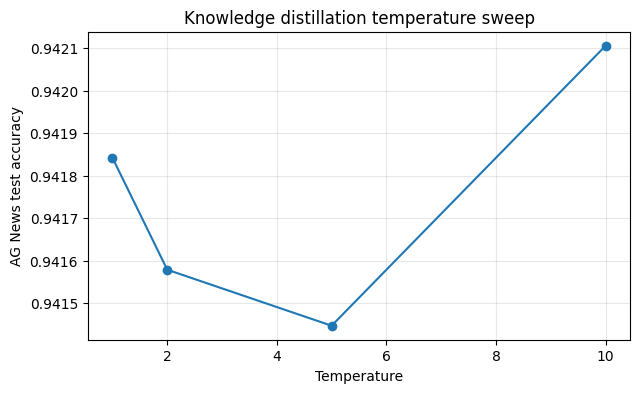

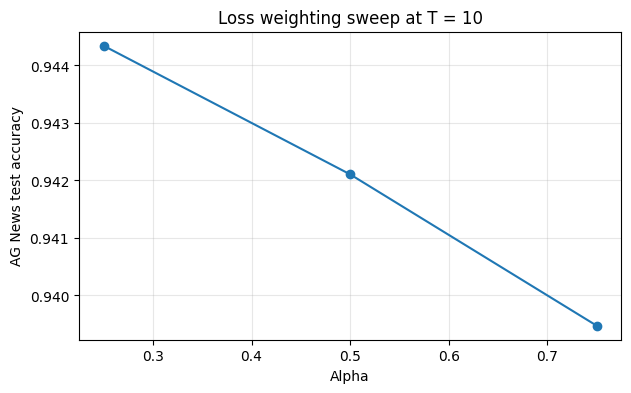

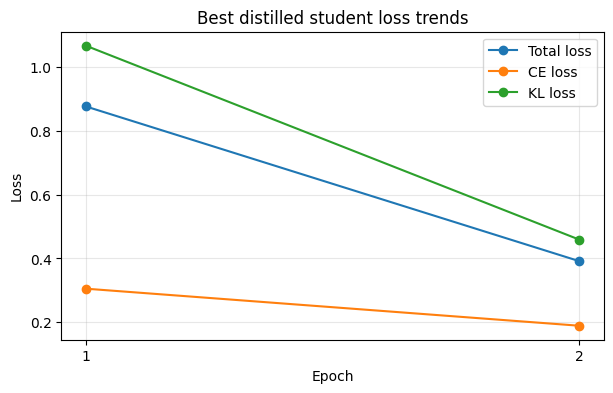

Best temperature: 10
Best alpha: 0.25
Best student accuracy: 0.9443421052631579


In [26]:
import matplotlib.pyplot as plt
import pandas as pd

temperature_df = pd.DataFrame({
    "Temperature": [1, 2, 5, 10],
    "Accuracy": [
        0.9418421052631579,
        0.9415789473684211,
        0.9414473684210526,
        0.9421052631578948
    ]
})

alpha_df = pd.DataFrame({
    "Alpha": [0.25, 0.50, 0.75],
    "Accuracy": [
        0.9443421052631579,
        0.9421052631578948,
        0.9394736842105263
    ]
})

best_loss_df = pd.DataFrame({
    "Epoch": [1, 2],
    "Total loss": [
        0.8761393925825754,
        0.39179320185979205
    ],
    "CE loss": [
        0.30539807580870887,
        0.18939704602876056
    ],
    "KL loss": [
        1.0663864979743958,
        0.45925858825445176
    ]
})

display(temperature_df)
display(alpha_df)
display(best_loss_df)

plt.figure(figsize=(7, 4))
plt.plot(
    temperature_df["Temperature"],
    temperature_df["Accuracy"],
    marker="o"
)
plt.xlabel("Temperature")
plt.ylabel("AG News test accuracy")
plt.title("Knowledge distillation temperature sweep")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    alpha_df["Alpha"],
    alpha_df["Accuracy"],
    marker="o"
)
plt.xlabel("Alpha")
plt.ylabel("AG News test accuracy")
plt.title("Loss weighting sweep at T = 10")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    best_loss_df["Epoch"],
    best_loss_df["Total loss"],
    marker="o",
    label="Total loss"
)
plt.plot(
    best_loss_df["Epoch"],
    best_loss_df["CE loss"],
    marker="o",
    label="CE loss"
)
plt.plot(
    best_loss_df["Epoch"],
    best_loss_df["KL loss"],
    marker="o",
    label="KL loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Best distilled student loss trends")
plt.xticks([1, 2])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Best temperature: 10")
print("Best alpha: 0.25")
print("Best student accuracy: 0.9443421052631579")

### Part 2 Findings

The best temperature was 10, which achieved an accuracy of 0.9421 during the temperature sweep. With the temperature fixed at 10, the loss weighting sweep showed that alpha = 0.25 performed best, reaching an accuracy of 0.9443. The final distilled DistilBERT student therefore used T = 10 and alpha = 0.25.

The teacher achieved 0.9446 accuracy on the AG News test set, compared with 0.9443 for the best distilled student, a decrease of only 0.0263 percentage points. At the same time, the student reduced p50 inference latency from 12.63 ms to 5.92 ms and p95 latency from 26.17 ms to 7.26 ms. Peak GPU memory decreased from 0.414 GB to 0.256 GB, while model size decreased from 418.58 MB to 256.11 MB. Therefore, the distilled student retained almost all of the teacher's predictive accuracy while substantially reducing inference latency, memory usage, and storage requirements.

### Where Compression Hurts

Sci Tech showed the largest degradation, with accuracy decreasing from 0.9268 for the teacher to 0.9163 for the student, a decrease of approximately 1.05 percentage points. The five inspected cases that the teacher classified correctly but the student misclassified were all predicted as Business by the student. These examples contain overlapping technology and commercial language, including companies, consumer products, markets, royalties, and acquisitions. This suggests that compression made the student more susceptible to strong business related lexical cues when the underlying article belonged to Sci Tech.

In [27]:
from pathlib import Path
from datetime import datetime

OUTPUT_DIR = Path("/content/hw12_final_files")
OUTPUT_DIR.mkdir(exist_ok=True)

metrics_text = """# HW12 Metrics

## Personal Parameters

SID4: 2046
SEED: 2046
SLICE: 46
HP_ID: 0
CLS_A: 6
CLS_B: 3

Hardware: Tesla T4

## Part 1: GPTQ

Base model: Qwen/Qwen3-0.6B

Revision: c1899de289a04d12100db370d81485cdf75e47ca

Evaluation dataset: WikiText2

| Configuration | Perplexity | p50 latency ms | p95 latency ms | Peak memory GB | Size on disk MB |
| --- | ---: | ---: | ---: | ---: | ---: |
| Base LLM | 20.0273 | 1323.85 | 1732.72 | 1.123 | 1147.81 |
| GPTQ 4 bit LLM | 24.0744 | 3234.89 | 6273.59 | 0.528 | 527.17 |

Memory reduction: 52.98%

Disk size reduction: 54.07%

Perplexity increase: 20.21%

p50 latency increase: 144.35%

p95 latency increase: 262.07%

## Part 2: Knowledge Distillation

Teacher: instructor provided BERT model trained on AG News

Student: distilbert base uncased

Best temperature: 10

Best alpha: 0.25

### Temperature Sweep

| Temperature | Accuracy |
| ---: | ---: |
| 1 | 0.941842 |
| 2 | 0.941579 |
| 5 | 0.941447 |
| 10 | 0.942105 |

### Loss Weighting Sweep

| Alpha | Accuracy |
| ---: | ---: |
| 0.25 | 0.944342 |
| 0.50 | 0.942105 |
| 0.75 | 0.939474 |

### Teacher versus Best Student

| Configuration | Accuracy | p50 latency ms | p95 latency ms | Peak memory GB | Size on disk MB |
| --- | ---: | ---: | ---: | ---: | ---: |
| Teacher BERT | 0.944605 | 12.63 | 26.17 | 0.414 | 418.58 |
| Best distilled student | 0.944342 | 5.92 | 7.26 | 0.256 | 256.11 |

Accuracy drop: 0.0263 percentage points

p50 latency reduction: 53.13%

p95 latency reduction: 72.26%

Peak memory reduction: 38.16%

Disk size reduction: 38.81%

### Per Class Accuracy

| Class | Teacher accuracy | Student accuracy | Degradation |
| --- | ---: | ---: | ---: |
| World | 0.949474 | 0.964737 | -0.015263 |
| Sports | 0.988421 | 0.988947 | -0.000526 |
| Business | 0.913684 | 0.907368 | 0.006316 |
| Sci Tech | 0.926842 | 0.916316 | 0.010526 |

Largest degradation class: Sci Tech
"""

run_log_text = f"""HW12 RUN LOG

Generated: {datetime.now().isoformat()}

SID4: 2046
SEED: 2046
Hardware: Tesla T4

PART 1

Base model:
Qwen/Qwen3-0.6B
Revision:
c1899de289a04d12100db370d81485cdf75e47ca

Base WikiText2 perplexity:
20.0273

Base p50 latency:
1323.85 ms

Base p95 latency:
1732.72 ms

Base peak GPU memory:
1.123 GB

Base disk size:
1147.81 MB

GPTQ:
4 bit
Calibration dataset: WikiText2

GPTQ WikiText2 perplexity:
24.0744

GPTQ p50 latency:
3234.89 ms

GPTQ p95 latency:
6273.59 ms

GPTQ peak GPU memory:
0.528 GB

GPTQ disk size:
527.17 MB

PART 2

Teacher:
BertForSequenceClassification
109485316 parameters

Student:
DistilBertForSequenceClassification
66956548 parameters

AG News training samples:
120000

AG News test samples:
7600

Teacher logits shape:
120000 x 4

Temperature sweep:
T1 accuracy 0.941842
T2 accuracy 0.941579
T5 accuracy 0.941447
T10 accuracy 0.942105

Best temperature:
10

Alpha sweep:
alpha 0.25 accuracy 0.944342
alpha 0.50 accuracy 0.942105
alpha 0.75 accuracy 0.939474

Best alpha:
0.25

Teacher final accuracy:
0.944605

Best student final accuracy:
0.944342

Teacher p50:
12.63 ms

Teacher p95:
26.17 ms

Student p50:
5.92 ms

Student p95:
7.26 ms

Teacher individual peak GPU memory:
0.414 GB

Student individual peak GPU memory:
0.256 GB

Teacher disk size:
418.58 MB

Student disk size:
256.11 MB

Largest degraded class:
Sci Tech

Teacher correct and student wrong examples in Sci Tech:
55
"""

ai_use_text = """# AI Use

I used ChatGPT to help structure the experiment workflow, implement the GPTQ evaluation and benchmarking code, implement the knowledge distillation loss and training loop, and organize the required measurements and analysis. I ran the experiments myself in Google Colab on a Tesla T4, inspected the outputs, and used the measured results from my executed notebook.

One specific issue in the generated workflow was the GPTQ environment setup. An early dependency installation resulted in a TorchAudio and PyTorch CUDA version mismatch, which caused GPTQModel imports to fail. The error reported that PyTorch and TorchAudio had been compiled with different CUDA versions. I identified the problem from the runtime stack trace and restarted with a cleaner dependency setup rather than using results from the inconsistent environment.

Another issue occurred when peak GPU memory for the teacher and student initially appeared identical because both models were simultaneously resident on the GPU. I recognized that this did not represent individual model memory. I unloaded both models and measured each model separately relative to the GPU allocation baseline. This produced individual peak measurements of 0.414 GB for the teacher and 0.256 GB for the student.

I verified that the base and GPTQ models used the same model ID, revision, WikiText2 evaluation, prompts, and Tesla T4 hardware. For distillation, I verified that each sweep condition initialized a fresh DistilBERT student using SEED 2046 while keeping the other training settings fixed. I also verified that the final teacher and student measurements used the same AG News test set and hardware.
"""

(OUTPUT_DIR / "METRICS.md").write_text(
    metrics_text,
    encoding="utf-8"
)

(OUTPUT_DIR / "RUN_LOG.txt").write_text(
    run_log_text,
    encoding="utf-8"
)

(OUTPUT_DIR / "AI_USE.md").write_text(
    ai_use_text,
    encoding="utf-8"
)

print("Created:")
print(OUTPUT_DIR / "METRICS.md")
print(OUTPUT_DIR / "RUN_LOG.txt")
print(OUTPUT_DIR / "AI_USE.md")

Created:
/content/hw12_final_files/METRICS.md
/content/hw12_final_files/RUN_LOG.txt
/content/hw12_final_files/AI_USE.md


In [28]:
from google.colab import files

files.download("/content/hw12_final_files/METRICS.md")
files.download("/content/hw12_final_files/RUN_LOG.txt")
files.download("/content/hw12_final_files/AI_USE.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import subprocess

repo = "/content/data266-2046"

print("Git status:")
print(
    subprocess.run(
        ["git", "-C", repo, "status", "--short"],
        capture_output=True,
        text=True
    ).stdout
)

print("Git user name:")
print(
    subprocess.run(
        ["git", "-C", repo, "config", "user.name"],
        capture_output=True,
        text=True
    ).stdout
)

print("Git user email:")
print(
    subprocess.run(
        ["git", "-C", repo, "config", "user.email"],
        capture_output=True,
        text=True
    ).stdout
)

Git status:
A  hw12/AI_USE.md
A  hw12/METRICS.md
A  hw12/RUN_LOG.txt

Git user name:

Git user email:



In [32]:
import subprocess

repo = "/content/data266-2046"

subprocess.run(
    [
        "git",
        "-C",
        repo,
        "config",
        "user.name",
        "Drashti Shah"
    ],
    check=True
)

subprocess.run(
    [
        "git",
        "-C",
        repo,
        "config",
        "user.email",
        "DrashtiShah23@users.noreply.github.com"
    ],
    check=True
)

subprocess.run(
    [
        "git",
        "-C",
        repo,
        "commit",
        "-m",
        "add HW12 metrics run log and AI use documentation"
    ],
    check=True
)

print("Commit created successfully.")

result = subprocess.run(
    [
        "git",
        "-C",
        repo,
        "log",
        "-1",
        "--oneline"
    ],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)

Commit created successfully.
e1b539b add HW12 metrics run log and AI use documentation



In [33]:
import subprocess

repo = "/content/data266-2046"

result = subprocess.run(
    [
        "git",
        "-C",
        repo,
        "push",
        "origin",
        "main"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print()
print("OUTPUT:")
print(result.stdout)
print()
print("ERROR:")
print(result.stderr)

Return code: 128

OUTPUT:


ERROR:
fatal: could not read Username for 'https://github.com': No such device or address

